# ****World Population Exploratory Data Analysis (EDA)****

**Project overview**

This project explores a country-level world population dataset using Python, Pandas, Matplotlib, and Seaborn. It examines population patterns across countries and continents, historical population changes, population density, growth rates, data quality, and relationships between numerical variables.

**Business purpose**

Population analysis can help public-sector planners, NGOs, researchers, and businesses understand where people are concentrated, how populations have changed, and where demand for services or infrastructure may be growing. The dataset supports descriptive analysis and prioritisation; it does not, by itself, explain why a population changed or predict future demand.

**Dataset at a glance**

The notebook's existing output shows 234 country/region records and 17 columns, including country identifiers, continent, population estimates for 1970–2022, land area, density, growth rate, and world-population share.

**Main analysis questions**

1. Which countries had the largest populations in 2022?

2. Which countries account for the largest share of the world population?

3. How have population levels changed over time, and how do continents compare?

4. Which continents have the largest average country population versus the largest total population?

5. How do population density and land area vary across countries?

6. Which numerical variables move together, and what can correlation tell us?

7. Are there extreme values or data-quality issues that should be considered before making decisions?

In [1]:
from google.colab import files

uploaded = files.upload()

Saving world_population.csv to world_population.csv


**Import necessary python's library for Analysis**

In [26]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv("world_population.csv")
df.head(n=2)

,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
0,36,AFG,Afghanistan,Kabul,Asia,41128771.00,38972230.00,33753499.00,28189672.00,19542982.00,10694796.00,12486631.00,10752971.00,652230.00,63.06,1.03,0.52
1,138,ALB,Albania,Tirana,Europe,2842321.00,2866849.00,2882481.00,2913399.00,3182021.00,3295066.00,2941651.00,2324731.00,28748.00,98.87,1.00,0.04


In [28]:
df.dtypes

,0
Rank,int64
CCA3,object
Country,object
Capital,object
Continent,object
2022 Population,float64
2020 Population,float64
2015 Population,float64
2010 Population,float64
2000 Population,float64


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 234 entries, 0 to 233
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Rank                         234 non-null    int64  
 1   CCA3                         234 non-null    object 
 2   Country                      234 non-null    object 
 3   Capital                      234 non-null    object 
 4   Continent                    234 non-null    object 
 5   2022 Population              230 non-null    float64
 6   2020 Population              233 non-null    float64
 7   2015 Population              230 non-null    float64
 8   2010 Population              227 non-null    float64
 9   2000 Population              227 non-null    float64
 10  1990 Population              229 non-null    float64
 11  1980 Population              229 non-null    float64
 12  1970 Population              230 non-null    float64
 13  Area (km²)          

# Changing display format of float data type columns.

In [11]:
pd.set_option("display.float_format", lambda x:"%.2f" %x)
df.head(2)

,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
0,36,AFG,Afghanistan,Kabul,Asia,41128771.00,38972230.00,33753499.00,28189672.00,19542982.00,10694796.00,12486631.00,10752971.00,652230.00,63.06,1.03,0.52
1,138,ALB,Albania,Tirana,Europe,2842321.00,2866849.00,2882481.00,2913399.00,3182021.00,3295066.00,2941651.00,2324731.00,28748.00,98.87,1.00,0.04


In [12]:
df.describe()

,Rank,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
count,234.00,230.00,233.00,230.00,227.00,227.00,229.00,229.00,230.00,232.00,230.00,232.00,234.00
mean,117.50,34632250.88,33600710.95,32066004.16,30270164.48,26840495.26,19330463.93,16282884.78,15866499.13,581663.75,456.81,1.01,0.43
std,67.69,137889172.44,135873196.61,131507146.34,126074183.54,113352454.57,81309624.96,69345465.54,68355859.75,1769133.06,2083.74,0.01,1.71
min,1.00,510.00,520.00,564.00,596.00,651.00,700.00,733.00,752.00,1.00,0.03,0.91,0.00
25%,59.25,419738.50,406471.00,394295.00,382726.50,329470.00,261928.00,223752.00,145880.50,2567.25,36.60,1.00,0.01
50%,117.50,5762857.00,5456681.00,5244415.00,4889741.00,4491202.00,3785847.00,3135123.00,2511718.00,77141.00,95.35,1.01,0.07
75%,175.75,22653719.00,21522626.00,19730853.75,16825852.50,15625467.00,11882762.00,9817257.00,8817329.00,414643.25,236.88,1.02,0.28
max,234.00,1425887337.00,1424929781.00,1393715448.00,1348191368.00,1264099069.00,1153704252.00,982372466.00,822534450.00,17098242.00,23172.27,1.07,17.88


**Checking missing values**

In [15]:
df.isnull().head(2)

,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
0,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False


In [19]:
df.isnull().sum()

,0
Rank,0
CCA3,0
Country,0
Capital,0
Continent,0
2022 Population,4
2020 Population,1
2015 Population,4
2010 Population,7
2000 Population,7


# How many unique values in each of these columns have?

In [21]:
df.nunique()

,0
Rank,234
CCA3,234
Country,234
Capital,234
Continent,6
2022 Population,230
2020 Population,233
2015 Population,230
2010 Population,227
2000 Population,227


**Univariate analysis:**

Question: What is the distribution of population across countries?

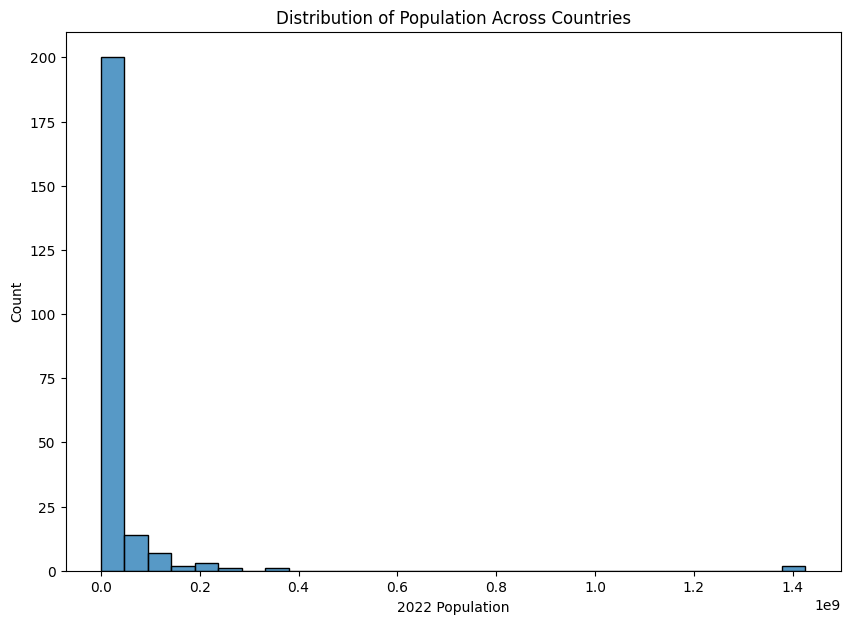

In [104]:
sns.histplot(data=df, x="2022 Population", bins=30)
plt.title("Distribution of Population Across Countries")
plt.show()

**Bivariate analysis:**

Question: Is a larger land area associated with a larger population?

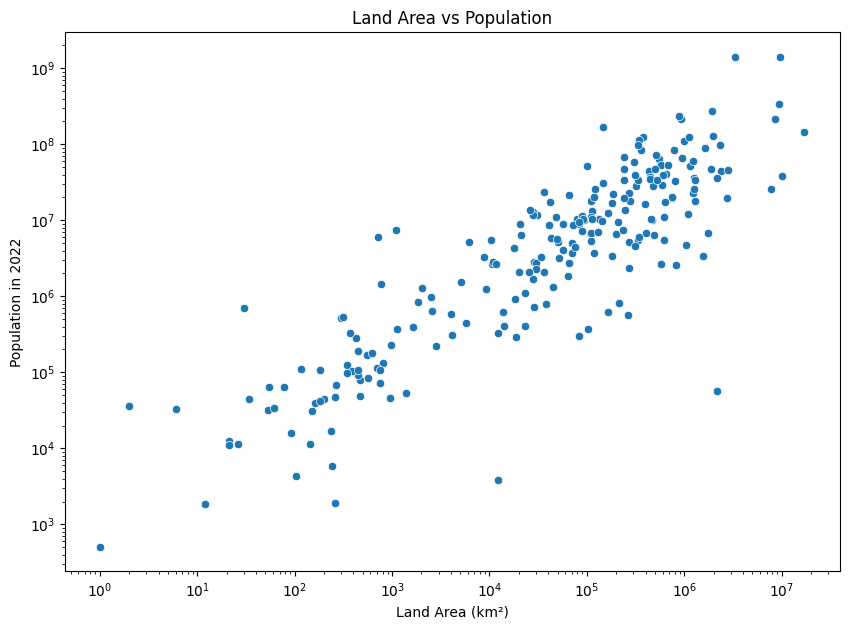

In [108]:
sns.scatterplot(
    df,
    x="Area (km²)",
    y="2022 Population"
)
plt.xscale("log")
plt.yscale("log")
plt.title("Land Area vs Population")
plt.xlabel("Land Area (km²)")
plt.ylabel("Population in 2022")
plt.show()

In [111]:
df[["Area (km²)", "2022 Population"]].corr()

,Area (km²),2022 Population
Area (km²),1.00,0.45
2022 Population,0.45,1.00


**Multivariate analysis:**

Question: How are population, land area, density, and growth rate related?

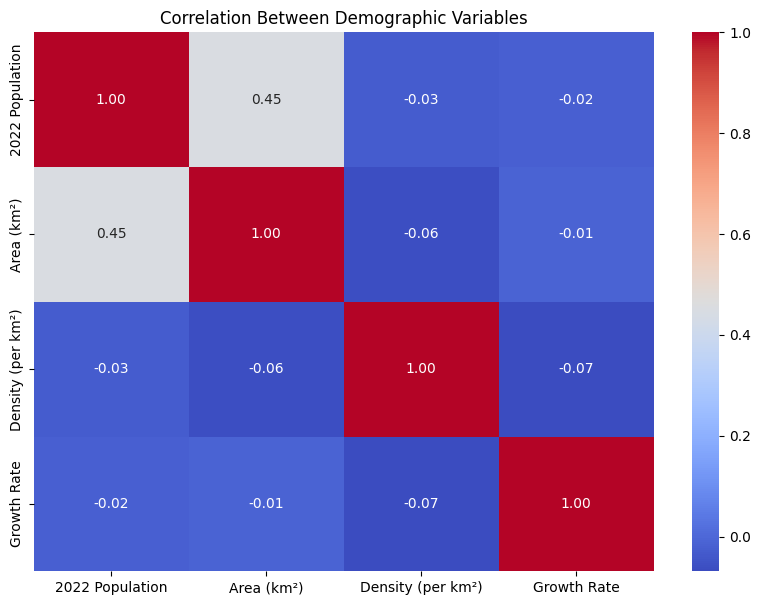

In [106]:
cols = [
    "2022 Population",
    "Area (km²)",
    "Density (per km²)",
    "Growth Rate"
]

sns.heatmap(
    df[cols].corr(numeric_only=True),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Between Demographic Variables")
plt.show()

**Top 5 Countries by population**

In [34]:
df.sort_values(by="2022 Population", ascending=False).head(5)

,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
41,1,CHN,China,Beijing,Asia,1425887337.00,1424929781.00,1393715448.00,1348191368.00,1264099069.00,1153704252.00,982372466.00,822534450.00,9706961.00,146.89,1.00,17.88
92,2,IND,India,New Delhi,Asia,1417173173.00,1396387127.00,1322866505.00,1240613620.00,1059633675.00,NaN,NaN,557501301.00,3287590.00,431.07,1.01,17.77
221,3,USA,United States,"Washington, D.C.",North America,338289857.00,335942003.00,324607776.00,311182845.00,282398554.00,248083732.00,223140018.00,200328340.00,9372610.00,36.09,1.00,4.24
93,4,IDN,Indonesia,Jakarta,Asia,275501339.00,271857970.00,259091970.00,244016173.00,214072421.00,182159874.00,148177096.00,115228394.00,1904569.00,144.65,1.01,3.45
156,5,PAK,Pakistan,Islamabad,Asia,235824862.00,227196741.00,210969298.00,194454498.00,154369924.00,115414069.00,80624057.00,59290872.00,881912.00,267.40,1.02,2.96


In [36]:
df.sort_values(by="2022 Population", ascending=False)[["Country", "2022 Population"]].head(5)

,Country,2022 Population
41,China,1425887337.00
92,India,1417173173.00
221,United States,338289857.00
93,Indonesia,275501339.00
156,Pakistan,235824862.00


In [35]:
df.sort_values(by="World Population Percentage", ascending=False).head(5)

,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
41,1,CHN,China,Beijing,Asia,1425887337.00,1424929781.00,1393715448.00,1348191368.00,1264099069.00,1153704252.00,982372466.00,822534450.00,9706961.00,146.89,1.00,17.88
92,2,IND,India,New Delhi,Asia,1417173173.00,1396387127.00,1322866505.00,1240613620.00,1059633675.00,NaN,NaN,557501301.00,3287590.00,431.07,1.01,17.77
221,3,USA,United States,"Washington, D.C.",North America,338289857.00,335942003.00,324607776.00,311182845.00,282398554.00,248083732.00,223140018.00,200328340.00,9372610.00,36.09,1.00,4.24
93,4,IDN,Indonesia,Jakarta,Asia,275501339.00,271857970.00,259091970.00,244016173.00,214072421.00,182159874.00,148177096.00,115228394.00,1904569.00,144.65,1.01,3.45
156,5,PAK,Pakistan,Islamabad,Asia,235824862.00,227196741.00,210969298.00,194454498.00,154369924.00,115414069.00,80624057.00,59290872.00,881912.00,267.40,1.02,2.96


**Correlation**

In [39]:
numeric_df = df.select_dtypes(include='number')
numeric_df.corr()

,Rank,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
Rank,1.00,-0.36,-0.36,-0.35,-0.35,-0.34,-0.33,-0.33,-0.34,-0.38,0.13,-0.22,-0.36
2022 Population,-0.36,1.00,1.00,1.00,1.00,0.99,0.99,0.99,0.97,0.45,-0.03,-0.02,1.00
2020 Population,-0.36,1.00,1.00,1.00,1.00,1.00,0.99,0.99,0.98,0.45,-0.03,-0.03,1.00
2015 Population,-0.35,1.00,1.00,1.00,1.00,1.00,0.99,0.99,0.98,0.46,-0.03,-0.03,1.00
2010 Population,-0.35,1.00,1.00,1.00,1.00,1.00,1.00,0.99,0.98,0.46,-0.03,-0.04,1.00
2000 Population,-0.34,0.99,1.00,1.00,1.00,1.00,1.00,1.00,0.99,0.47,-0.03,-0.05,0.99
1990 Population,-0.33,0.99,0.99,0.99,1.00,1.00,1.00,1.00,1.00,0.52,-0.03,-0.07,0.99
1980 Population,-0.33,0.99,0.99,0.99,0.99,1.00,1.00,1.00,1.00,0.53,-0.03,-0.08,0.99
1970 Population,-0.34,0.97,0.98,0.98,0.98,0.99,1.00,1.00,1.00,0.51,-0.03,-0.08,0.97
Area (km²),-0.38,0.45,0.45,0.46,0.46,0.47,0.52,0.53,0.51,1.00,-0.06,-0.01,0.45


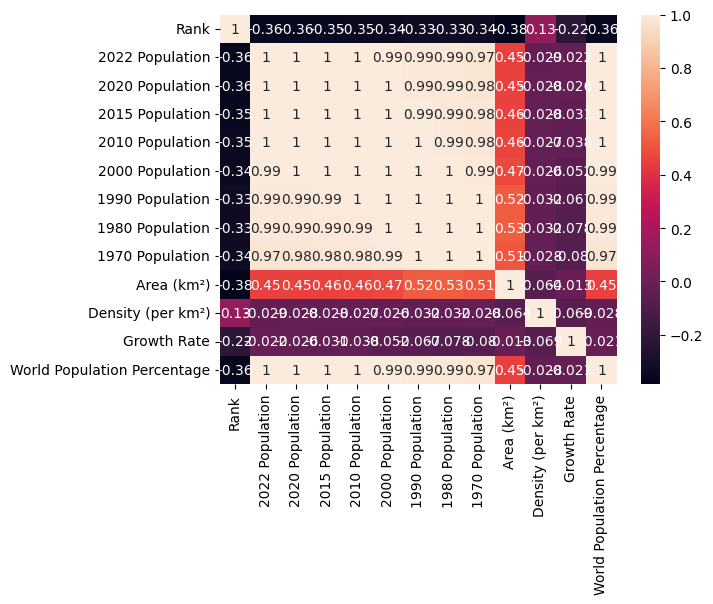

In [43]:
sns.heatmap(numeric_df.corr(), annot=True)
plt.rcParams["figure.figsize"]=(10,7)
plt.show()

In [47]:
df.groupby("Continent").mean(numeric_only=True)

,Rank,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
Continent,,,,,,,,,,,,,
Africa,92.16,25455879.68,23871435.26,21419703.57,18898197.31,14598365.95,11376964.52,8586031.98,6567175.27,537879.30,126.41,1.02,0.31
Asia,77.56,96327387.31,94955134.37,89165003.64,89087770.00,80580835.11,48639995.33,40278333.33,43839877.83,642762.82,1025.02,1.01,1.18
Europe,124.50,15055371.82,14915843.92,15027454.12,14712278.68,14817685.71,14785203.94,14200004.52,13118479.82,460208.22,663.32,1.00,0.19
North America,160.93,15007403.40,14855914.82,14259596.25,13568016.28,12151739.60,10531660.62,9207334.03,7885865.15,606104.45,272.49,1.00,0.19
Oceania,188.52,2046386.32,1910148.96,1756664.48,1613163.65,1357512.09,1162774.87,996532.17,846968.26,370220.91,132.54,1.01,0.02
South America,97.57,31201186.29,30823574.50,29509599.71,26789395.54,25015888.69,21224743.93,17270643.29,13781939.71,1301302.85,20.97,1.01,0.39


In [48]:
df.groupby("Continent")["2022 Population"].mean(numeric_only=True)

,2022 Population
Continent,
Africa,25455879.68
Asia,96327387.31
Europe,15055371.82
North America,15007403.40
Oceania,2046386.32
South America,31201186.29


In [50]:
df[df["Continent"].str.contains("Oceania")]

,Rank,CCA3,Country,Capital,Continent,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
3,213,ASM,American Samoa,Pago Pago,Oceania,44273.00,46189.00,51368.00,54849.00,58230.00,47818.00,32886.00,27075.00,199.00,222.48,0.98,0.00
11,55,AUS,Australia,Canberra,Oceania,26177413.00,25670051.00,23820236.00,22019168.00,19017963.00,17048003.00,14706322.00,12595034.00,7692024.00,3.40,1.01,0.33
44,223,COK,Cook Islands,Avarua,Oceania,17011.00,17029.00,17695.00,17212.00,15897.00,17123.00,17651.00,20470.00,236.00,72.08,1.00,0.00
66,162,FJI,Fiji,Suva,Oceania,929766.00,920422.00,917200.00,905169.00,832509.00,780430.00,644582.00,527634.00,18272.00,50.88,1.01,0.01
70,183,PYF,French Polynesia,Papeete,Oceania,306279.00,301920.00,291787.00,283788.00,250927.00,211089.00,163591.00,117891.00,4167.00,73.50,1.01,0.00
81,191,GUM,Guam,Hagåtña,Oceania,171774.00,169231.00,167978.00,164905.00,160188.00,138263.00,110286.00,88300.00,549.00,312.89,1.01,0.00
107,192,KIR,Kiribati,Tarawa,Oceania,131232.00,126463.00,116707.00,107995.00,88826.00,75124.00,60813.00,57437.00,811.00,161.81,1.02,0.00
126,215,MHL,Marshall Islands,Majuro,Oceania,41569.00,43413.00,49410.00,53416.00,54224.00,46047.00,31988.00,23969.00,181.00,229.66,0.99,0.00
132,194,FSM,Micronesia,Palikir,Oceania,114164.00,112106.00,109462.00,107588.00,111709.00,98603.00,76299.00,58989.00,702.00,162.63,1.01,0.00
142,225,NRU,Nauru,Yaren,Oceania,12668.00,12315.00,11185.00,10241.00,10377.00,9598.00,7635.00,6663.00,21.00,603.24,1.01,0.00


In [51]:
df.groupby("Continent").mean(numeric_only=True).sort_values(by="2022 Population", ascending=False)

,Rank,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
Continent,,,,,,,,,,,,,
Asia,77.56,96327387.31,94955134.37,89165003.64,89087770.00,80580835.11,48639995.33,40278333.33,43839877.83,642762.82,1025.02,1.01,1.18
South America,97.57,31201186.29,30823574.50,29509599.71,26789395.54,25015888.69,21224743.93,17270643.29,13781939.71,1301302.85,20.97,1.01,0.39
Africa,92.16,25455879.68,23871435.26,21419703.57,18898197.31,14598365.95,11376964.52,8586031.98,6567175.27,537879.30,126.41,1.02,0.31
Europe,124.50,15055371.82,14915843.92,15027454.12,14712278.68,14817685.71,14785203.94,14200004.52,13118479.82,460208.22,663.32,1.00,0.19
North America,160.93,15007403.40,14855914.82,14259596.25,13568016.28,12151739.60,10531660.62,9207334.03,7885865.15,606104.45,272.49,1.00,0.19
Oceania,188.52,2046386.32,1910148.96,1756664.48,1613163.65,1357512.09,1162774.87,996532.17,846968.26,370220.91,132.54,1.01,0.02


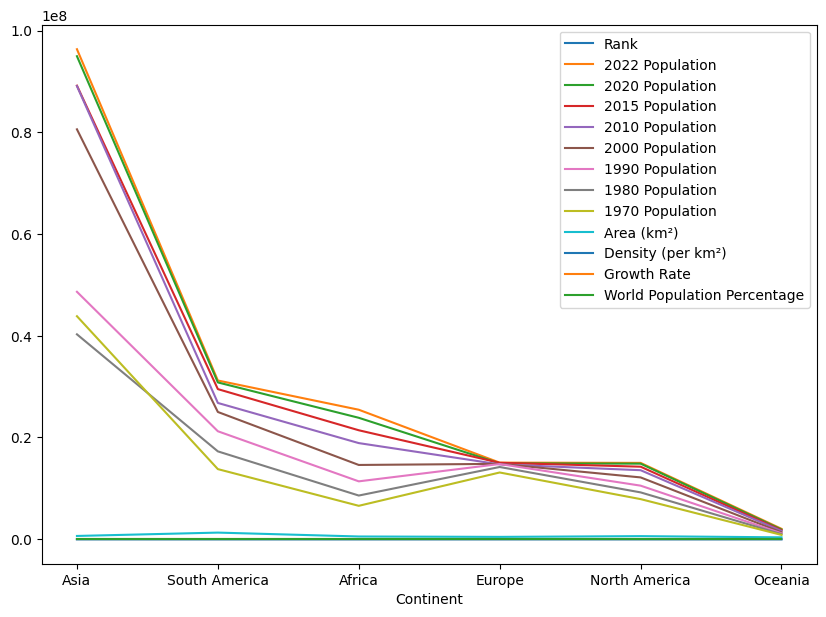

In [63]:
df_2=df.groupby("Continent").mean(numeric_only=True).sort_values(by="2022 Population", ascending=False).plot()

In [67]:
df_2

<Axes: xlabel='Continent'>

In [81]:
# Group the data to get the aggregated DataFrame
df_grouped = df.groupby("Continent")[['2022 Population',
       '2020 Population', '2015 Population', '2010 Population',
       '2000 Population', '1990 Population', '1980 Population',
       '1970 Population', 'Area (km²)', 'Density (per km²)', 'Growth Rate',
       'World Population Percentage']].mean(numeric_only=True).sort_values(by="2022 Population", ascending=False)

df_grouped

,2022 Population,2020 Population,2015 Population,2010 Population,2000 Population,1990 Population,1980 Population,1970 Population,Area (km²),Density (per km²),Growth Rate,World Population Percentage
Continent,,,,,,,,,,,,
Asia,96327387.31,94955134.37,89165003.64,89087770.00,80580835.11,48639995.33,40278333.33,43839877.83,642762.82,1025.02,1.01,1.18
South America,31201186.29,30823574.50,29509599.71,26789395.54,25015888.69,21224743.93,17270643.29,13781939.71,1301302.85,20.97,1.01,0.39
Africa,25455879.68,23871435.26,21419703.57,18898197.31,14598365.95,11376964.52,8586031.98,6567175.27,537879.30,126.41,1.02,0.31
Europe,15055371.82,14915843.92,15027454.12,14712278.68,14817685.71,14785203.94,14200004.52,13118479.82,460208.22,663.32,1.00,0.19
North America,15007403.40,14855914.82,14259596.25,13568016.28,12151739.60,10531660.62,9207334.03,7885865.15,606104.45,272.49,1.00,0.19
Oceania,2046386.32,1910148.96,1756664.48,1613163.65,1357512.09,1162774.87,996532.17,846968.26,370220.91,132.54,1.01,0.02


In [83]:
# Transpose the DataFrame and plot the transposed result
df_3=df_grouped.transpose()

<Axes: >

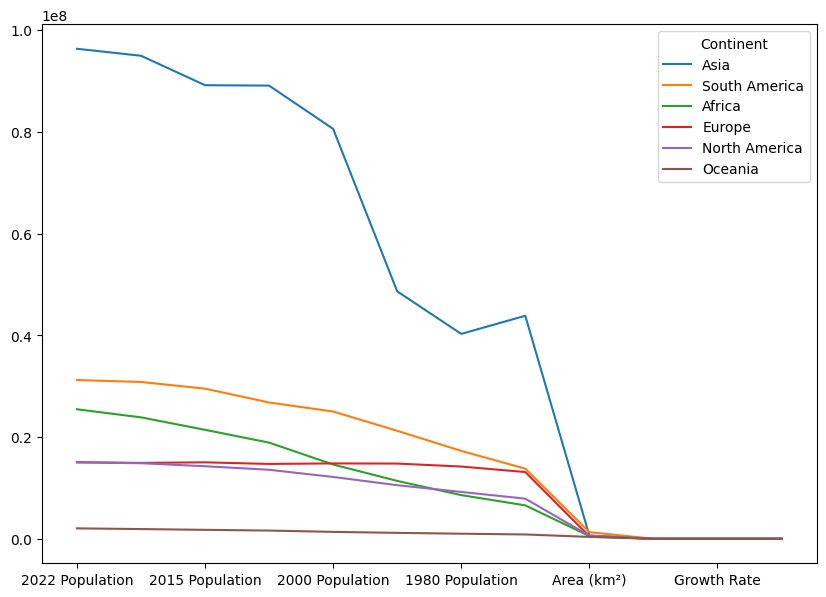

In [84]:
df_3.plot()

<Axes: title={'center': 'Population Trend by Continent'}>

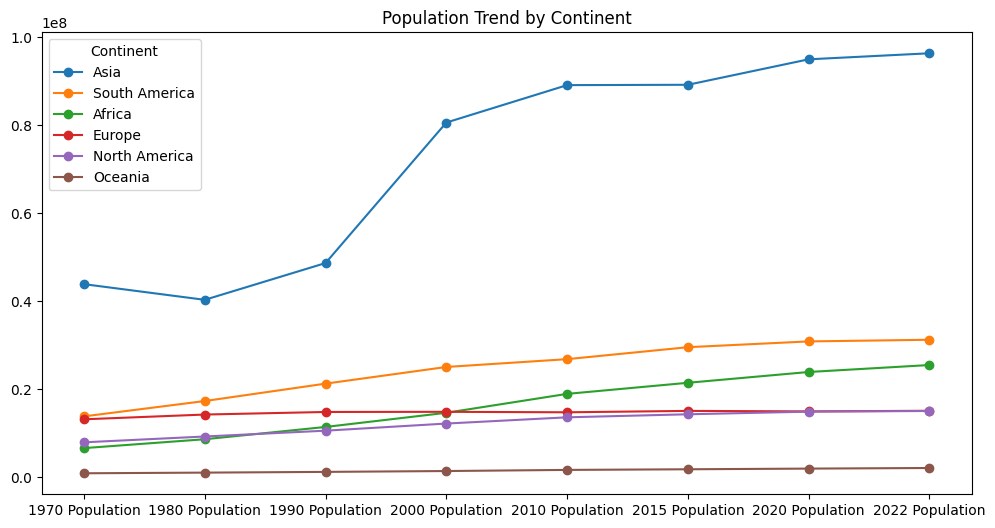

In [86]:
# Select population columns in chronological order
population_cols = [
    "1970 Population",
    "1980 Population",
    "1990 Population",
    "2000 Population",
    "2010 Population",
    "2015 Population",
    "2020 Population",
    "2022 Population"
]

# Transpose to plot years on the x-axis
df_trend = df_grouped[population_cols].T

# Plot the time trend
df_trend.plot(
    kind="line",
    marker="o",
    figsize=(12, 6),
    title="Population Trend by Continent"
)

<Axes: >

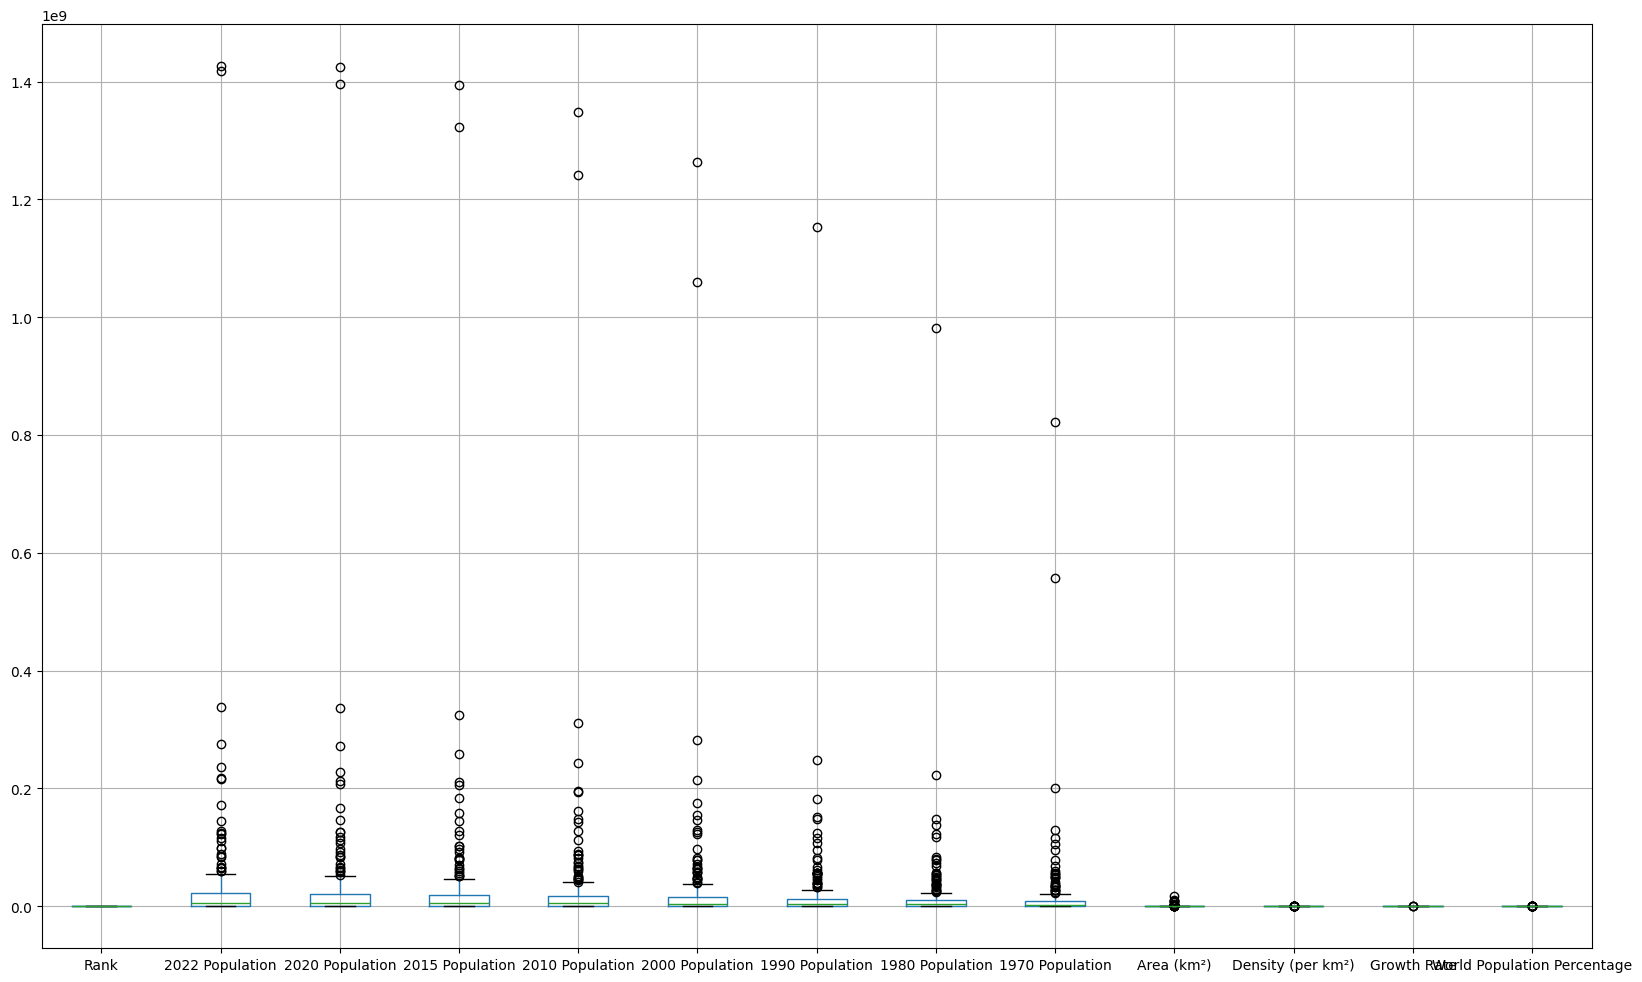

In [91]:
df.boxplot(figsize=(20,12))

<Axes: title={'center': '2022 Population'}, xlabel='Continent'>

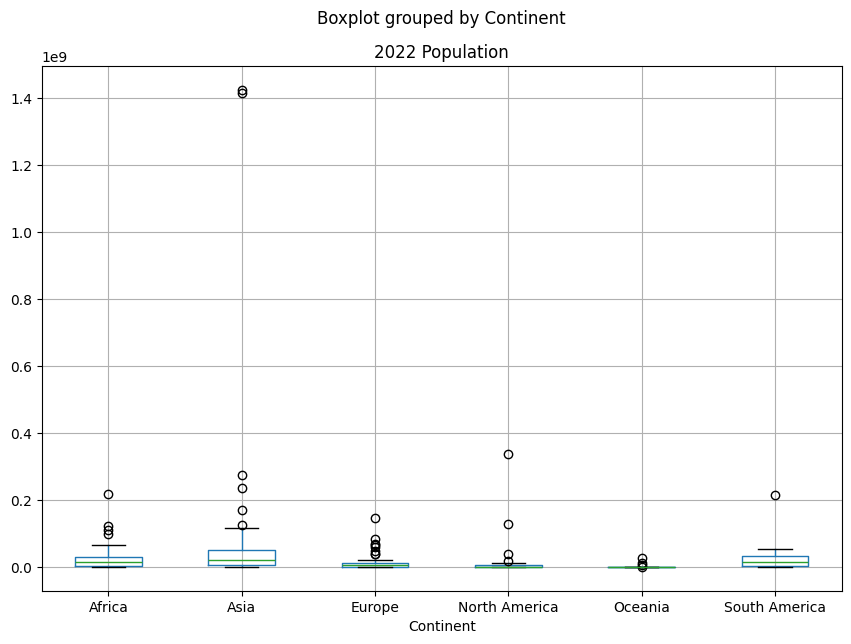

In [92]:
df.boxplot(column="2022 Population", by="Continent")

In [96]:
df.select_dtypes(include="object")

,CCA3,Country,Capital,Continent
0,AFG,Afghanistan,Kabul,Asia
1,ALB,Albania,Tirana,Europe
2,DZA,Algeria,Algiers,Africa
3,ASM,American Samoa,Pago Pago,Oceania
4,AND,Andorra,Andorra la Vella,Europe
...,...,...,...,...
229,WLF,Wallis and Futuna,Mata-Utu,Oceania
230,ESH,Western Sahara,El Aaiún,Africa
231,YEM,Yemen,Sanaa,Asia
232,ZMB,Zambia,Lusaka,Africa


In [97]:
# Business Question 1: Which countries had the largest populations in 2022?
top_countries = (
    df.nlargest(5, "2022 Population")[["Country", "Continent", "2022 Population",
                                      "World Population Percentage"]]
    .reset_index(drop=True)
)
display(top_countries)

largest = top_countries.iloc[0]
print(f"Finding: {largest['Country']} has the largest 2022 population in this dataset "
      f"({largest['2022 Population']:,.0f} people).")
print("Business use: large-population countries can be prioritised for high-level "
      "service-capacity and market-sizing analysis, then investigated with local data.")

,Country,Continent,2022 Population,World Population Percentage
0,China,Asia,1425887337.00,17.88
1,India,Asia,1417173173.00,17.77
2,United States,North America,338289857.00,4.24
3,Indonesia,Asia,275501339.00,3.45
4,Pakistan,Asia,235824862.00,2.96


Finding: China has the largest 2022 population in this dataset (1,425,887,337 people).
Business use: large-population countries can be prioritised for high-level service-capacity and market-sizing analysis, then investigated with local data.


In [98]:
# Business Question 2: Which countries represent the largest shares of world population?
share_cols = ["Country", "2022 Population", "World Population Percentage"]
top_share = (
    df.nlargest(5, "World Population Percentage")[share_cols]
    .reset_index(drop=True)
)
display(top_share)

share_total = df["World Population Percentage"].sum(min_count=1)
print(f"Finding: the five countries above have the largest reported population shares. "
      f"The sum of the dataset's reported country shares is {share_total:.2f}%.")
print("Business use: population share helps identify countries with substantial global "
      "demographic importance. Treat the share as a dataset-provided estimate.")

,Country,2022 Population,World Population Percentage
0,China,1425887337.00,17.88
1,India,1417173173.00,17.77
2,United States,338289857.00,4.24
3,Indonesia,275501339.00,3.45
4,Pakistan,235824862.00,2.96


Finding: the five countries above have the largest reported population shares. The sum of the dataset's reported country shares is 99.93%.
Business use: population share helps identify countries with substantial global demographic importance. Treat the share as a dataset-provided estimate.


,1970 Population,1980 Population,1990 Population,2000 Population,2010 Population,2015 Population,2020 Population,2022 Population
Continent,,,,,,,,
Africa,361194640.00,480817791.00,637110013.00,817508493.00,1020502655.00,1156663993.00,1360671810.00,1425529262.00
Asia,2104314136.00,1933360000.00,2334719776.00,3706718415.00,4187125190.00,4458250182.00,4652801584.00,4720041978.00
Europe,655923991.00,681600217.00,709689789.00,726066600.00,735613934.00,736345252.00,745792196.00,737713219.00
North America,315434606.00,368293361.00,421266425.00,486069584.00,542720651.00,570383850.00,594236593.00,600296136.00
Oceania,19480270.00,22920240.00,26743822.00,31222778.00,37102764.00,40403283.00,43933426.00,45020499.00
South America,192947156.00,241789006.00,297146415.00,325206553.00,348262142.00,413134396.00,431530043.00,436816608.00


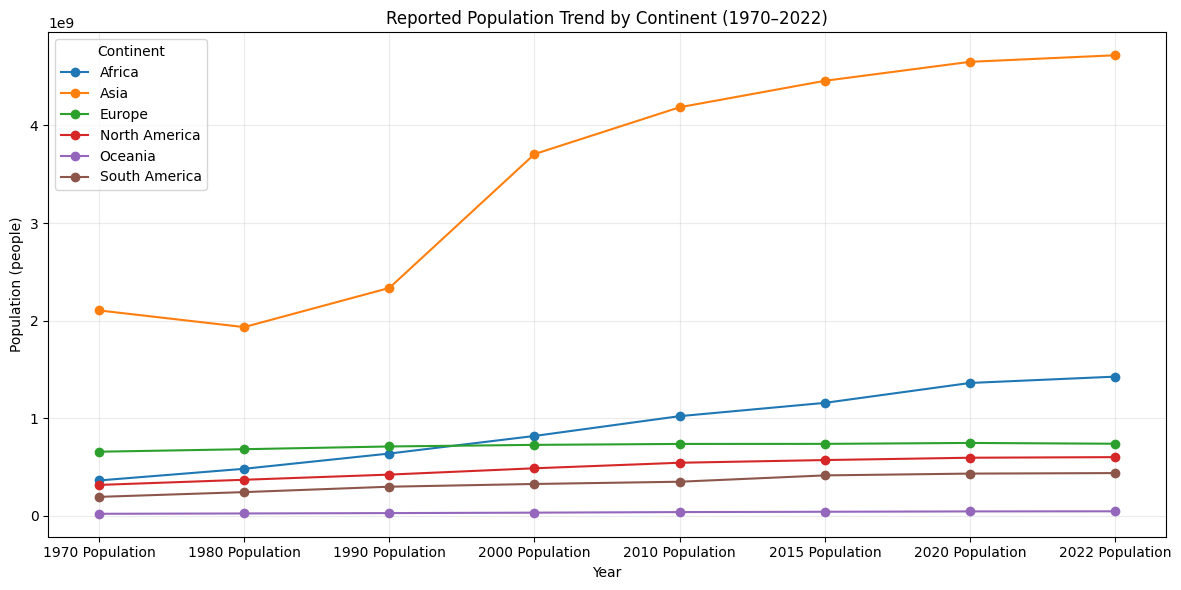

Finding: use the chart to compare the direction and scale of population change across continents. Because the dataset has missing historical values, totals may not cover every country in every year.


In [99]:
# Business Question 3: How has population changed over time by continent?
population_cols = [
    "1970 Population", "1980 Population", "1990 Population", "2000 Population",
    "2010 Population", "2015 Population", "2020 Population", "2022 Population"
]

# Sum country populations to estimate continent-level totals for each year.
# Pandas sum skips missing values; report the number of available records per year too.
continent_totals = df.groupby("Continent")[population_cols].sum(min_count=1)
display(continent_totals)

continent_totals.T.plot(
    kind="line", marker="o", figsize=(12, 6),
    title="Reported Population Trend by Continent (1970–2022)"
)
plt.xlabel("Year")
plt.ylabel("Population (people)")
plt.xticks(rotation=0)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print("Finding: use the chart to compare the direction and scale of population change "
      "across continents. Because the dataset has missing historical values, totals may "
      "not cover every country in every year.")

In [100]:
# Business Question 4: Which continents have the largest average country population
# and which have the largest total population in 2022?
continent_summary = df.groupby("Continent").agg(
    country_records=("Country", "count"),
    mean_country_population_2022=("2022 Population", "mean"),
    total_population_2022=("2022 Population", lambda s: s.sum(min_count=1)),
    mean_density=("Density (per km²)", "mean"),
    mean_growth_rate=("Growth Rate", "mean")
).sort_values("total_population_2022", ascending=False)

display(continent_summary)

total_leader = continent_summary["total_population_2022"].idxmax()
average_leader = continent_summary["mean_country_population_2022"].idxmax()
print(f"Finding: by summed 2022 population, {total_leader} ranks highest among continents "
      f"in this dataset.")
print(f"By average population per country/record, {average_leader} ranks highest.")
print("Interpretation: a continent can rank high in total population because it contains "
      "many countries and/or very populous countries. Average country population is a "
      "different metric and should not be described as the continent's total population.")

,country_records,mean_country_population_2022,total_population_2022,mean_density,mean_growth_rate
Continent,,,,,
Asia,50,96327387.31,4720041978.00,1025.02,1.01
Africa,57,25455879.68,1425529262.00,126.41,1.02
Europe,50,15055371.82,737713219.00,663.32,1.00
North America,40,15007403.40,600296136.00,272.49,1.00
South America,14,31201186.29,436816608.00,20.97,1.01
Oceania,23,2046386.32,45020499.00,132.54,1.01


Finding: by summed 2022 population, Asia ranks highest among continents in this dataset.
By average population per country/record, Asia ranks highest.
Interpretation: a continent can rank high in total population because it contains many countries and/or very populous countries. Average country population is a different metric and should not be described as the continent's total population.


In [101]:
# Business Question 5: Which countries have the highest population density?
density_cols = ["Country", "Continent", "2022 Population", "Area (km²)",
                "Density (per km²)"]
top_density = (
    df.dropna(subset=["Density (per km²)"])
      .nlargest(10, "Density (per km²)")[density_cols]
      .reset_index(drop=True)
)
display(top_density)

print("Business use: density can help flag places where transport, housing, utilities, "
      "healthcare, and other services may face high spatial demand. Density alone does "
      "not prove that an area is overcrowded; local infrastructure and settlement patterns matter.")

,Country,Continent,2022 Population,Area (km²),Density (per km²)
0,Macau,Asia,695168.00,30.00,23172.27
1,Monaco,Europe,36469.00,2.00,18234.50
2,Singapore,Asia,5975689.00,710.00,8416.46
3,Hong Kong,Asia,7488865.00,1104.00,6783.39
4,Gibraltar,Europe,32649.00,6.00,5441.50
5,Bahrain,Asia,1472233.00,765.00,1924.49
6,Maldives,Asia,523787.00,300.00,1745.96
7,Malta,Europe,533286.00,316.00,1687.61
8,Sint Maarten,North America,44175.00,34.00,1299.26
9,Bermuda,North America,64184.00,54.00,1188.59


Business use: density can help flag places where transport, housing, utilities, healthcare, and other services may face high spatial demand. Density alone does not prove that an area is overcrowded; local infrastructure and settlement patterns matter.


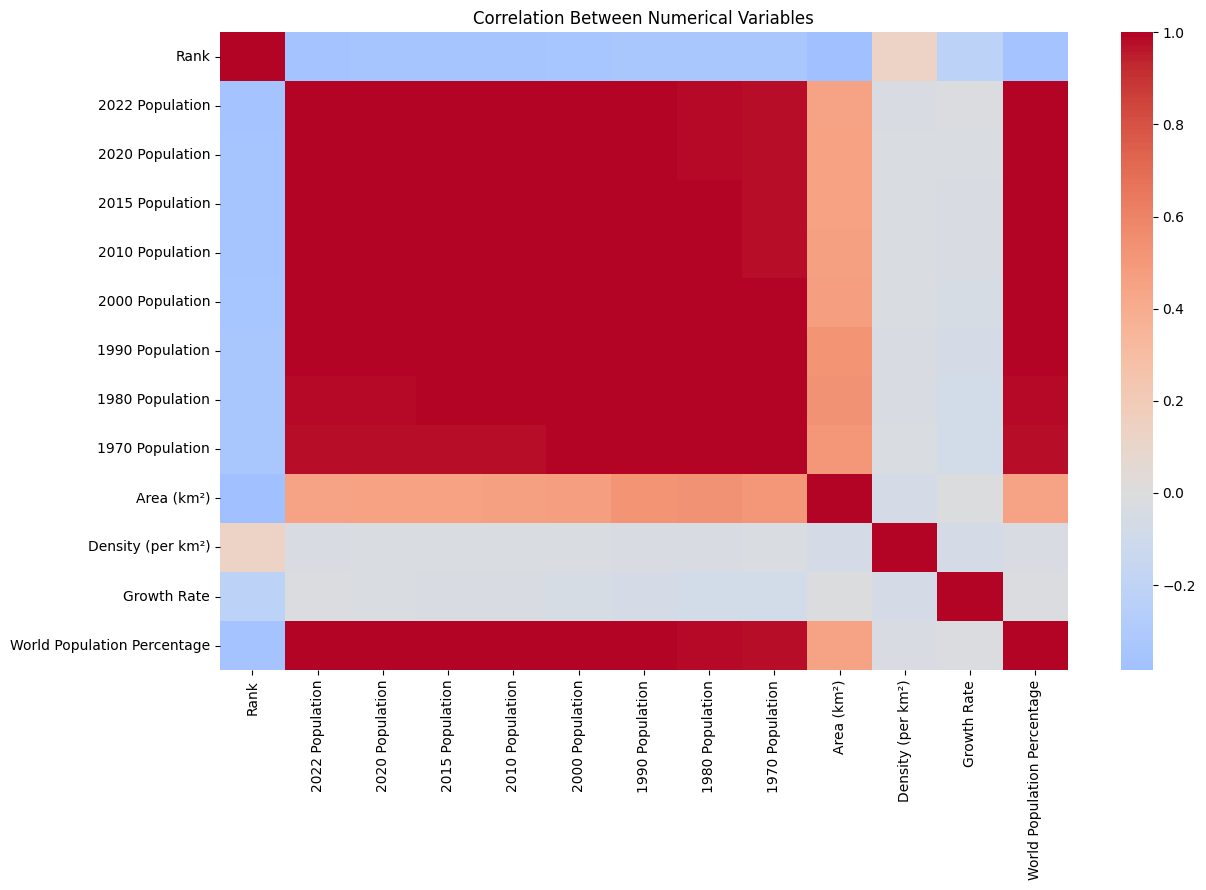

Correlation
2022 Population World Population Percentage         1.00
                2020 Population                     1.00
2020 Population World Population Percentage         1.00
2015 Population 2010 Population                     1.00
2020 Population 2015 Population                     1.00
2022 Population 2015 Population                     1.00
2015 Population World Population Percentage         1.00
1990 Population 1980 Population                     1.00
1980 Population 1970 Population                     1.00
2000 Population 1990 Population                     1.00

Interpretation: correlations close to +1 indicate variables that tend to increase together; values close to -1 indicate an inverse relationship. Correlation does not establish causation. Population columns from different years are expected to be strongly related because they measure similar quantities over time.


In [102]:
# Business Question 6: Which numerical variables are strongly correlated?
numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr(numeric_only=True)

plt.figure(figsize=(13, 9))
sns.heatmap(correlation, cmap="coolwarm", center=0, annot=False)
plt.title("Correlation Between Numerical Variables")
plt.tight_layout()
plt.show()

# Show strongest non-duplicate pairs for a quick review.
corr_pairs = correlation.where(
    __import__("numpy").triu(__import__("numpy").ones(correlation.shape), k=1).astype(bool)
).stack().sort_values(key=lambda s: s.abs(), ascending=False)
display(corr_pairs.head(10).rename("Correlation").to_frame())

print("Interpretation: correlations close to +1 indicate variables that tend to increase "
      "together; values close to -1 indicate an inverse relationship. Correlation does not "
      "establish causation. Population columns from different years are expected to be "
      "strongly related because they measure similar quantities over time.")

In [103]:
# Business Question 7: What data-quality issues should be addressed?
missing_summary = (
    df.isna().sum()
      .rename("Missing values")
      .to_frame()
      .assign(**{"Missing %": lambda x: (x["Missing values"] / len(df) * 100).round(2)})
      .query("`Missing values` > 0")
      .sort_values("Missing values", ascending=False)
)
display(missing_summary)

print(f"Dataset size: {df.shape[0]} rows × {df.shape[1]} columns")
print(f"Duplicate full rows: {df.duplicated().sum()}")
print("Recommendation: inspect missing population values before year-to-year comparisons; "
      "do not automatically replace missing population with zero. Check units, definitions, "
      "and whether growth rate is stored as a multiplier or a percentage before reporting it.")

,Missing values,Missing %
2010 Population,7,2.99
2000 Population,7,2.99
1990 Population,5,2.14
1980 Population,5,2.14
1970 Population,4,1.71
2022 Population,4,1.71
2015 Population,4,1.71
Density (per km²),4,1.71
Area (km²),2,0.85
Growth Rate,2,0.85


Dataset size: 234 rows × 17 columns
Duplicate full rows: 0
Recommendation: inspect missing population values before year-to-year comparisons; do not automatically replace missing population with zero. Check units, definitions, and whether growth rate is stored as a multiplier or a percentage before reporting it.


**Overall conclusions and business recommendations**

What this EDA can tell us
- Population concentration: ranking countries by 2022 population and world-population share identifies where a large share of people live.
- Demographic change: historical population columns allow comparison of reported changes across years and continents.
- Planning context: population density, land area, and growth rate can help frame questions about infrastructure, public services, and market opportunities.
- Data quality: missing values and extreme differences between countries must be considered before using the results for decisions.
- Relationships: correlation helps identify variables that move together, but does not explain causes.

**Recommendations**

1. Use continent totals when comparing the number of people across continents; use mean country population only when the question concerns the typical country/record.
2. Prioritise deeper country-level analysis for high-population and high-density places, then combine this dataset with local data on age, income, urbanisation, infrastructure, and service access.
3. Validate missing values and metric definitions before publishing statistics.
4. Avoid making causal claims or forecasts from descriptive EDA alone. Forecasting would require a suitable time-series approach and additional validation.
5. For a portfolio presentation, highlight the business question, the chart/table used, the key finding printed by the notebook, and the decision it could inform.

**Limitations**

- The dataset contains snapshots for selected years, not annual observations for every year.
- Several fields have missing values; available records may differ by year.
- Country-level averages and continent-level sums answer different questions.
- Population data alone cannot explain demographic drivers or determine actual demand for a service or product.